## Load data

In [1]:
import pandas as pd

In [2]:
df = pd.read_csv("train_v9rqX0R.csv")
df_test = pd.read_csv("test_AbJTz2l.csv")

In [3]:
df.head()

,Item_Identifier,Item_Weight,Item_Fat_Content,Item_Visibility,Item_Type,Item_MRP,Outlet_Identifier,Outlet_Establishment_Year,Outlet_Size,Outlet_Location_Type,Outlet_Type,Item_Outlet_Sales
0,FDA15,9.30,Low Fat,0.016047,Dairy,249.8092,OUT049,1999,Medium,Tier 1,Supermarket Type1,3735.1380
1,DRC01,5.92,Regular,0.019278,Soft Drinks,48.2692,OUT018,2009,Medium,Tier 3,Supermarket Type2,443.4228
2,FDN15,17.50,Low Fat,0.016760,Meat,141.6180,OUT049,1999,Medium,Tier 1,Supermarket Type1,2097.2700
3,FDX07,19.20,Regular,0.000000,Fruits and Vegetables,182.0950,OUT010,1998,NaN,Tier 3,Grocery Store,732.3800
4,NCD19,8.93,Low Fat,0.000000,Household,53.8614,OUT013,1987,High,Tier 3,Supermarket Type1,994.7052


In [4]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 8523 entries, 0 to 8522
Data columns (total 12 columns):
 #   Column                     Non-Null Count  Dtype  
---  ------                     --------------  -----  
 0   Item_Identifier            8523 non-null   str    
 1   Item_Weight                7060 non-null   float64
 2   Item_Fat_Content           8523 non-null   str    
 3   Item_Visibility            8523 non-null   float64
 4   Item_Type                  8523 non-null   str    
 5   Item_MRP                   8523 non-null   float64
 6   Outlet_Identifier          8523 non-null   str    
 7   Outlet_Establishment_Year  8523 non-null   int64  
 8   Outlet_Size                6113 non-null   str    
 9   Outlet_Location_Type       8523 non-null   str    
 10  Outlet_Type                8523 non-null   str    
 11  Item_Outlet_Sales          8523 non-null   float64
dtypes: float64(4), int64(1), str(7)
memory usage: 799.2 KB


In [5]:
df.describe()

,Item_Weight,Item_Visibility,Item_MRP,Outlet_Establishment_Year,Item_Outlet_Sales
count,7060.000000,8523.000000,8523.000000,8523.000000,8523.000000
mean,12.857645,0.066132,140.992782,1997.831867,2181.288914
std,4.643456,0.051598,62.275067,8.371760,1706.499616
min,4.555000,0.000000,31.290000,1985.000000,33.290000
25%,8.773750,0.026989,93.826500,1987.000000,834.247400
50%,12.600000,0.053931,143.012800,1999.000000,1794.331000
75%,16.850000,0.094585,185.643700,2004.000000,3101.296400
max,21.350000,0.328391,266.888400,2009.000000,13086.964800


In [6]:
y = df["Item_Outlet_Sales"]
X = df.drop(columns=["Item_Outlet_Sales"], errors="ignore")

In [7]:
print("Independent variables:", X.shape[1])
print("Dependent variables:", 1)

Independent variables: 11
Dependent variables: 1


In [8]:
df.isnull().sum()

Item_Identifier                 0
Item_Weight                  1463
Item_Fat_Content                0
Item_Visibility                 0
Item_Type                       0
Item_MRP                        0
Outlet_Identifier               0
Outlet_Establishment_Year       0
Outlet_Size                  2410
Outlet_Location_Type            0
Outlet_Type                     0
Item_Outlet_Sales               0
dtype: int64

In [9]:
df_test.isnull().sum()

Item_Identifier                 0
Item_Weight                   976
Item_Fat_Content                0
Item_Visibility                 0
Item_Type                       0
Item_MRP                        0
Outlet_Identifier               0
Outlet_Establishment_Year       0
Outlet_Size                  1606
Outlet_Location_Type            0
Outlet_Type                     0
dtype: int64

In [10]:
# find unique values of each column
print(df.nunique())

Item_Identifier              1559
Item_Weight                   415
Item_Fat_Content                5
Item_Visibility              7880
Item_Type                      16
Item_MRP                     5938
Outlet_Identifier              10
Outlet_Establishment_Year       9
Outlet_Size                     3
Outlet_Location_Type            3
Outlet_Type                     4
Item_Outlet_Sales            3493
dtype: int64


## Step 1 — Univariate Analysis

In [11]:
# Percentage distribution of the categorical columns
print(df['Item_Fat_Content'].value_counts(normalize=True)*100)

Item_Fat_Content
Low Fat    59.709023
Regular    33.896515
LF          3.707615
reg         1.372756
low fat     1.314091
Name: proportion, dtype: float64


In [12]:
print(df['Item_Type'].value_counts(normalize=True)*100)

Item_Type
Fruits and Vegetables    14.455004
Snack Foods              14.079549
Household                10.676992
Frozen Foods             10.043412
Dairy                     8.001877
Canned                    7.614690
Baking Goods              7.602957
Health and Hygiene        6.101138
Soft Drinks               5.221166
Meat                      4.986507
Breads                    2.944972
Hard Drinks               2.510853
Others                    1.982870
Starchy Foods             1.736478
Breakfast                 1.290625
Seafood                   0.750909
Name: proportion, dtype: float64


In [13]:
print(df['Outlet_Identifier'].value_counts(normalize=True)*100)

Outlet_Identifier
OUT027    10.970316
OUT013    10.935117
OUT049    10.911651
OUT046    10.911651
OUT035    10.911651
OUT045    10.899918
OUT018    10.888185
OUT017    10.864719
OUT010     6.511792
OUT019     6.195002
Name: proportion, dtype: float64


In [14]:
print(df['Outlet_Size'].value_counts(normalize=True, dropna=False)*100)

Outlet_Size
Medium    32.770151
NaN       28.276428
Small     28.018303
High      10.935117
Name: proportion, dtype: float64


In [15]:
print(df['Outlet_Location_Type'].value_counts(normalize=True)*100)

Outlet_Location_Type
Tier 3    39.305409
Tier 2    32.676288
Tier 1    28.018303
Name: proportion, dtype: float64


In [16]:
print(df['Outlet_Type'].value_counts(normalize=True)*100)

Outlet_Type
Supermarket Type1    65.434706
Grocery Store        12.706793
Supermarket Type3    10.970316
Supermarket Type2    10.888185
Name: proportion, dtype: float64


In [17]:
print(df['Outlet_Establishment_Year'].value_counts(normalize=True)*100)

Outlet_Establishment_Year
1985    17.165317
1987    10.935117
1999    10.911651
1997    10.911651
2004    10.911651
2002    10.899918
2009    10.888185
2007    10.864719
1998     6.511792
Name: proportion, dtype: float64


In [18]:
import seaborn as sns
import matplotlib.pyplot as plt

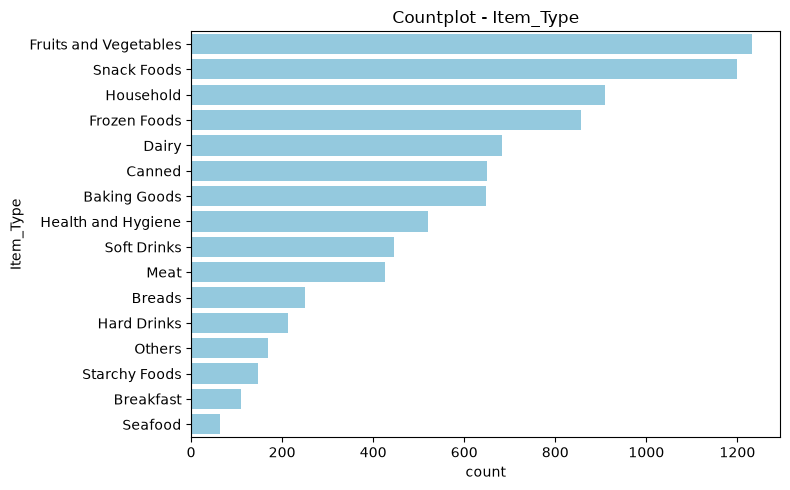

In [19]:
plt.figure(figsize=(8, 5))
sns.countplot(y=df["Item_Type"], order=df["Item_Type"].value_counts().index, color="skyblue")
plt.title("Countplot - Item_Type")
plt.tight_layout()
plt.show()

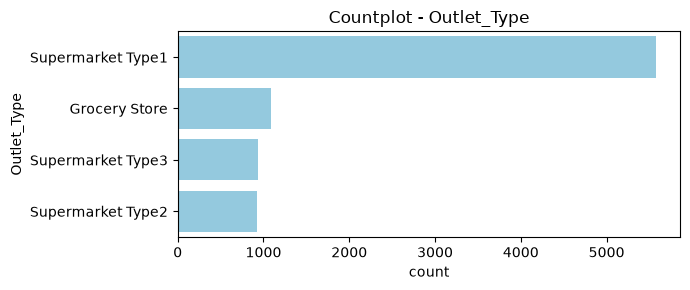

In [20]:
plt.figure(figsize=(7, 3))
sns.countplot(y=df["Outlet_Type"], order=df["Outlet_Type"].value_counts().index, color="skyblue")
plt.title("Countplot - Outlet_Type")
plt.tight_layout()
plt.show()

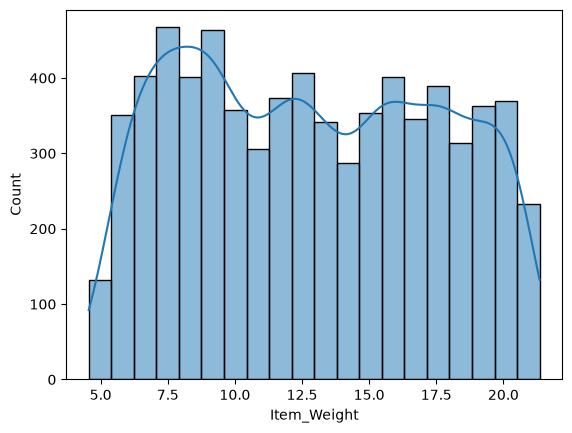

In [21]:
sns.histplot(df["Item_Weight"], kde=True)
plt.show()

In [22]:
print("Skewness:", df["Item_Weight"].skew())

Skewness: 0.08242620912212255


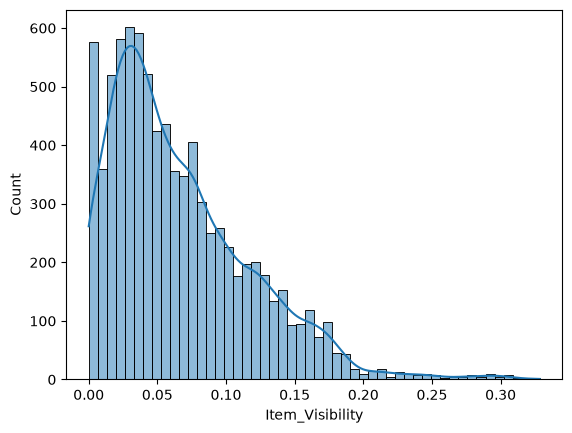

In [23]:
sns.histplot(df["Item_Visibility"], kde=True)
plt.show()

In [24]:
print("Skewness:", df["Item_Visibility"].skew())

Skewness: 1.1670905496918407


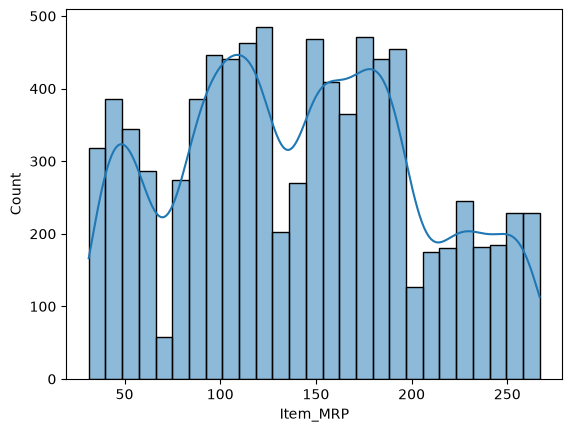

In [25]:
sns.histplot(df["Item_MRP"], kde=True)
plt.show()

In [26]:
print("Skewness:", df["Item_MRP"].skew())

Skewness: 0.12720226831105305


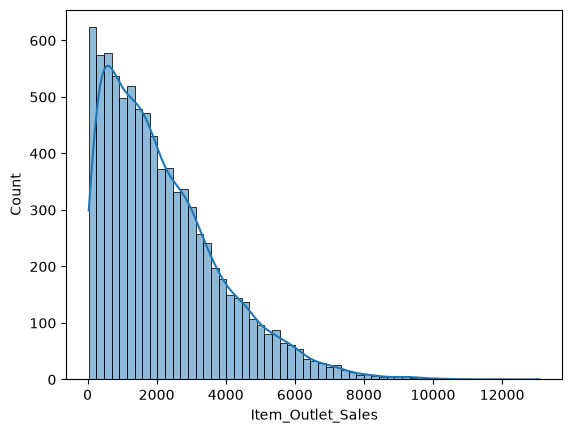

In [27]:
sns.histplot(df["Item_Outlet_Sales"], kde=True)
plt.show()

In [28]:
print("Skewness:", df["Item_Outlet_Sales"].skew())

Skewness: 1.1775306028542794


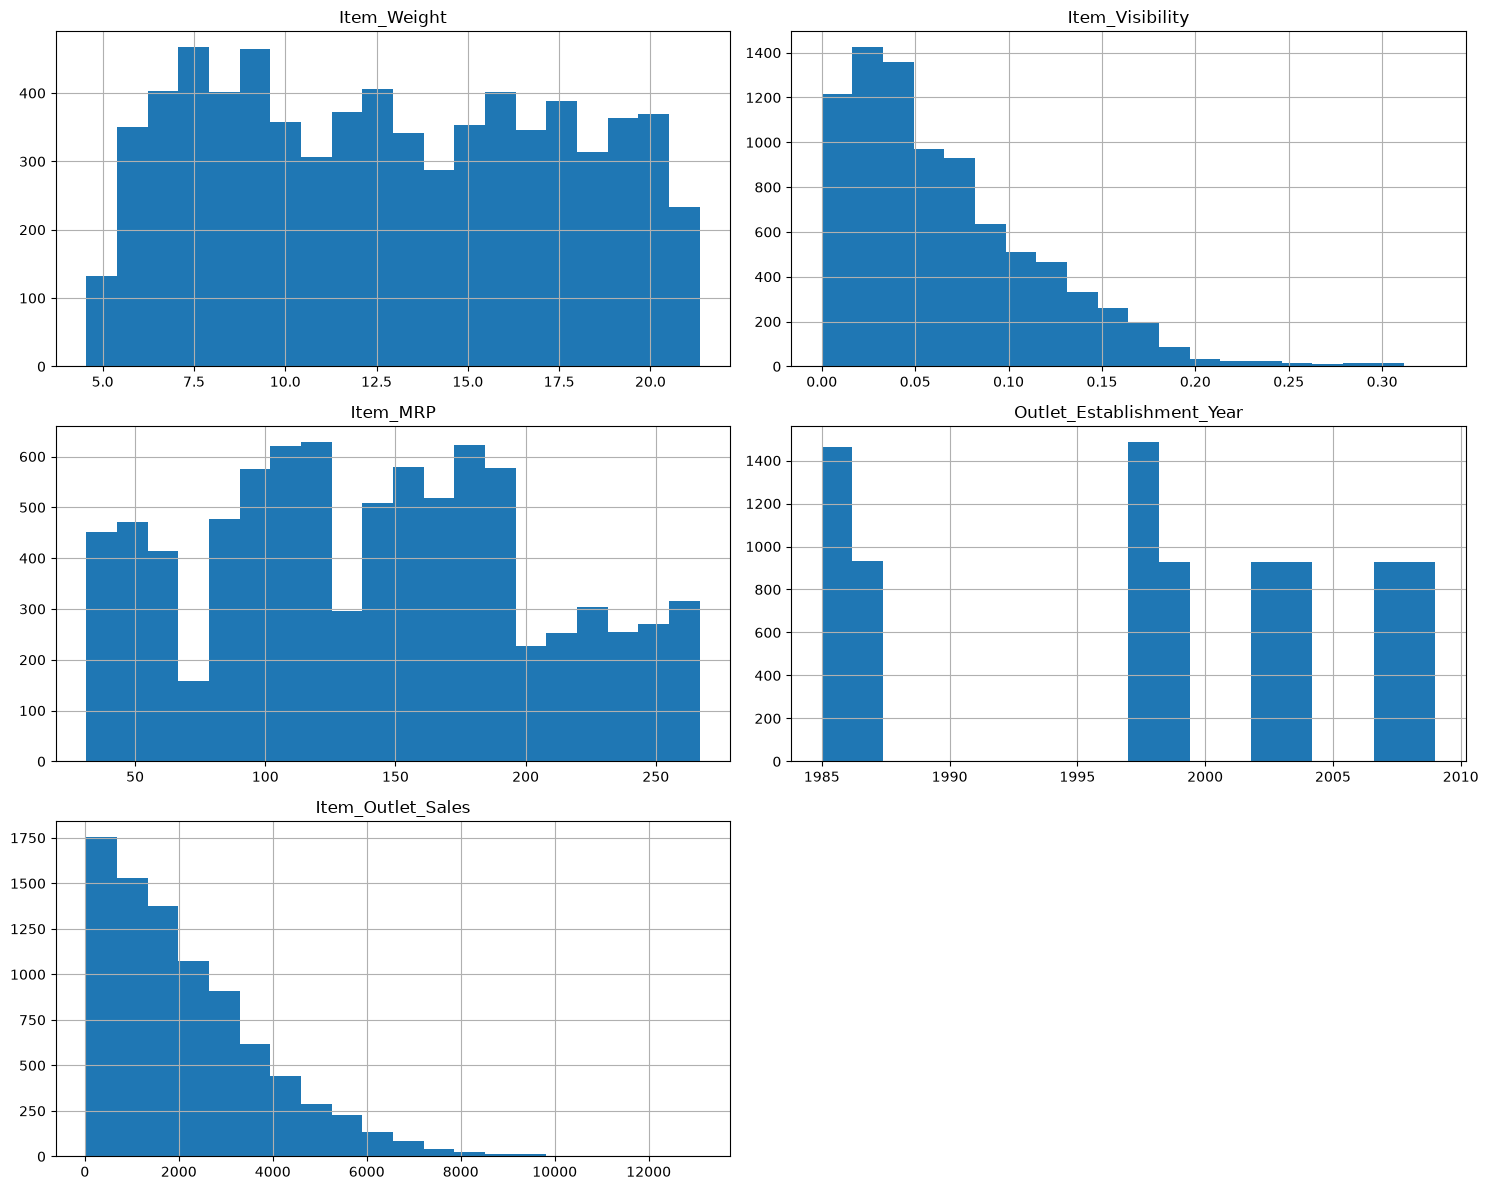

In [29]:
import matplotlib.pyplot as plt
df.hist(figsize=(15, 12), bins=20)
plt.tight_layout()
plt.show()

In [30]:
# Select numerical features
numerical_features = ["Item_Weight", "Item_Visibility", "Item_MRP", "Item_Outlet_Sales"]

In [31]:
print("Descriptive Statistics for Numerical Features:")
display(df[numerical_features].describe())

Descriptive Statistics for Numerical Features:


,Item_Weight,Item_Visibility,Item_MRP,Item_Outlet_Sales
count,7060.000000,8523.000000,8523.000000,8523.000000
mean,12.857645,0.066132,140.992782,2181.288914
std,4.643456,0.051598,62.275067,1706.499616
min,4.555000,0.000000,31.290000,33.290000
25%,8.773750,0.026989,93.826500,834.247400
50%,12.600000,0.053931,143.012800,1794.331000
75%,16.850000,0.094585,185.643700,3101.296400
max,21.350000,0.328391,266.888400,13086.964800


In [32]:
# Boxplots for numerical features to visualize outliers
cols = 2
rows = (len(numerical_features) + cols - 1) // cols
plt.figure(figsize=(12, rows * 4))

<Figure size 1200x800 with 0 Axes>

<Figure size 1200x800 with 0 Axes>

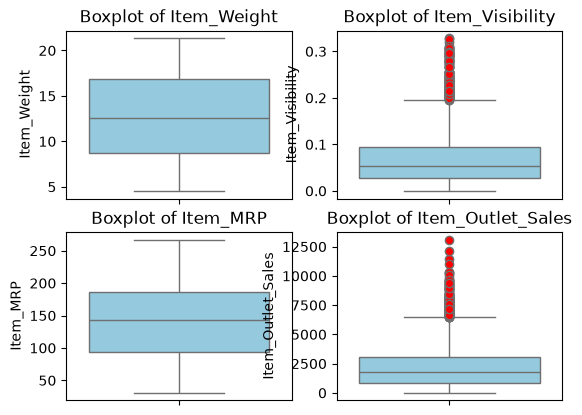

In [33]:
for i, col in enumerate(numerical_features, start=1):
    plt.subplot(rows, cols, i)
    sns.boxplot(y=df[col], color='skyblue',
                flierprops={'marker': 'o', 'markerfacecolor': 'red'})
    plt.title(f'Boxplot of {col}')

In [34]:
plt.tight_layout()
plt.show()

<Figure size 640x480 with 0 Axes>

## Step 2 — Bivariate Analysis

In [35]:
import seaborn as sns
import matplotlib.pyplot as plt

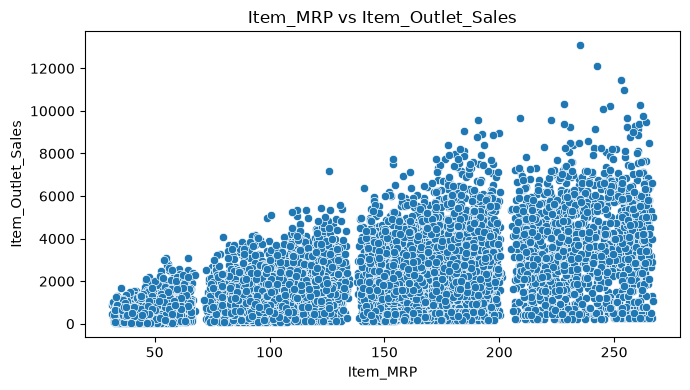

In [36]:
plt.figure(figsize=(7, 4))
sns.scatterplot(data=df, x='Item_MRP', y='Item_Outlet_Sales')
plt.title('Item_MRP vs Item_Outlet_Sales')
plt.tight_layout()
plt.show()

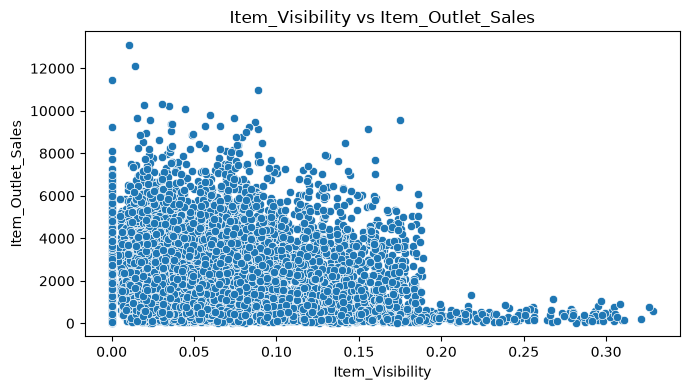

In [37]:
plt.figure(figsize=(7, 4))
sns.scatterplot(data=df, x='Item_Visibility', y='Item_Outlet_Sales')
plt.title('Item_Visibility vs Item_Outlet_Sales')
plt.tight_layout()
plt.show()

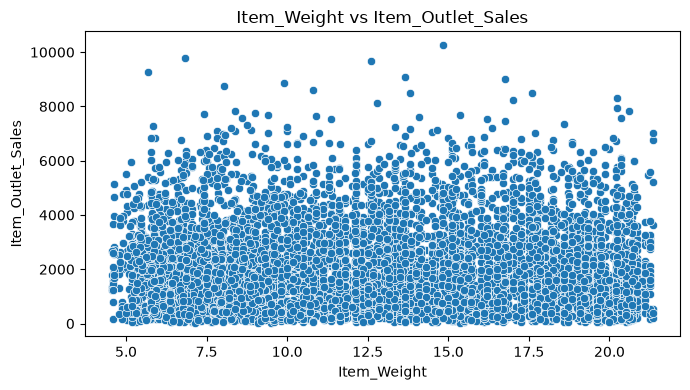

In [38]:
plt.figure(figsize=(7, 4))
sns.scatterplot(data=df, x='Item_Weight', y='Item_Outlet_Sales')
plt.title('Item_Weight vs Item_Outlet_Sales')
plt.tight_layout()
plt.show()

In [39]:
# Calculate correlations between all numeric variables
correlation_matrix = df.corr(numeric_only=True)

In [40]:
# Set figure size
plt.figure(figsize=(8, 8))

<Figure size 800x800 with 0 Axes>

<Figure size 800x800 with 0 Axes>

<Axes: >

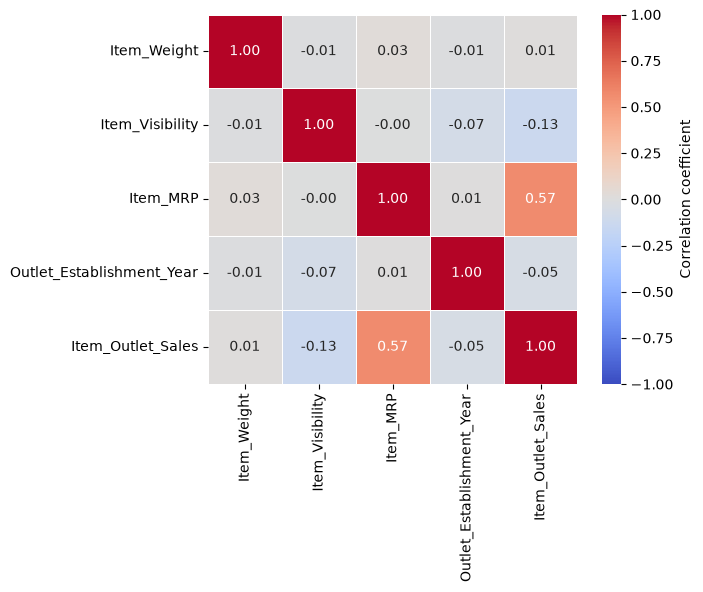

In [41]:
# Create full correlation heatmap
sns.heatmap(
    correlation_matrix,
    annot=True,             # Display correlation values
    fmt=".2f",              # Two decimal places
    cmap="coolwarm",        # Blue = negative, red = positive
    vmin=-1,
    vmax=1,
    center=0,
    square=True,
    linewidths=0.5,
    cbar_kws={"label": "Correlation coefficient"}
)

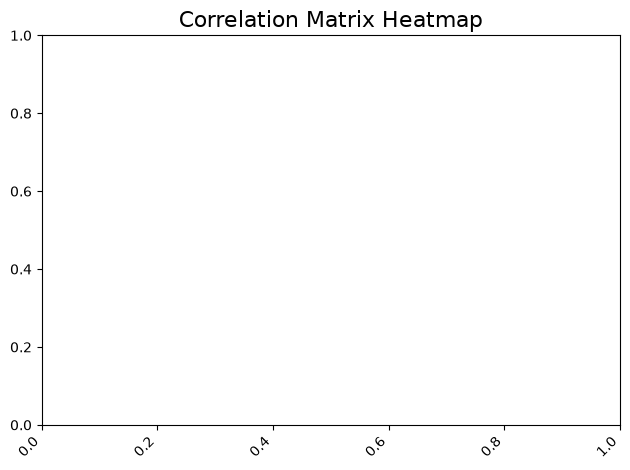

In [42]:
plt.title("Correlation Matrix Heatmap", fontsize=16)
plt.xticks(rotation=45, ha="right")
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()

In [43]:
# Mean Item_Outlet_Sales for each value of the categorical columns
print(df.groupby('Item_Fat_Content')['Item_Outlet_Sales'].mean())

Item_Fat_Content
LF         2073.551928
Low Fat    2164.477336
Regular    2235.186702
low fat    2087.740737
reg        1962.192268
Name: Item_Outlet_Sales, dtype: float64


In [44]:
df.groupby('Item_Type')['Item_Outlet_Sales'].mean()

Item_Type
Baking Goods             1952.971207
Breads                   2204.132226
Breakfast                2111.808651
Canned                   2225.194904
Dairy                    2232.542597
Frozen Foods             2132.867744
Fruits and Vegetables    2289.009592
Hard Drinks              2139.221622
Health and Hygiene       2010.000265
Household                2258.784300
Meat                     2158.977911
Others                   1926.139702
Seafood                  2326.065928
Snack Foods              2277.321739
Soft Drinks              2006.511735
Starchy Foods            2374.332773
Name: Item_Outlet_Sales, dtype: float64

In [45]:
df.groupby('Outlet_Identifier')['Item_Outlet_Sales'].mean()

Outlet_Identifier
OUT010     339.351662
OUT013    2298.995256
OUT017    2340.675263
OUT018    1995.498739
OUT019     340.329723
OUT027    3694.038558
OUT035    2438.841866
OUT045    2192.384798
OUT046    2277.844267
OUT049    2348.354635
Name: Item_Outlet_Sales, dtype: float64

In [46]:
df.groupby('Outlet_Size')['Item_Outlet_Sales'].mean()

Outlet_Size
High      2298.995256
Medium    2681.603542
Small     1912.149161
Name: Item_Outlet_Sales, dtype: float64

In [47]:
df.groupby('Outlet_Location_Type')['Item_Outlet_Sales'].mean()

Outlet_Location_Type
Tier 1    1876.909159
Tier 2    2323.990559
Tier 3    2279.627651
Name: Item_Outlet_Sales, dtype: float64

In [48]:
df.groupby('Outlet_Type')['Item_Outlet_Sales'].mean()

Outlet_Type
Grocery Store         339.828500
Supermarket Type1    2316.181148
Supermarket Type2    1995.498739
Supermarket Type3    3694.038558
Name: Item_Outlet_Sales, dtype: float64

In [49]:
df.groupby('Outlet_Establishment_Year')['Item_Outlet_Sales'].mean()

Outlet_Establishment_Year
1985    2483.677474
1987    2298.995256
1997    2277.844267
1998     339.351662
1999    2348.354635
2002    2192.384798
2004    2438.841866
2007    2340.675263
2009    1995.498739
Name: Item_Outlet_Sales, dtype: float64

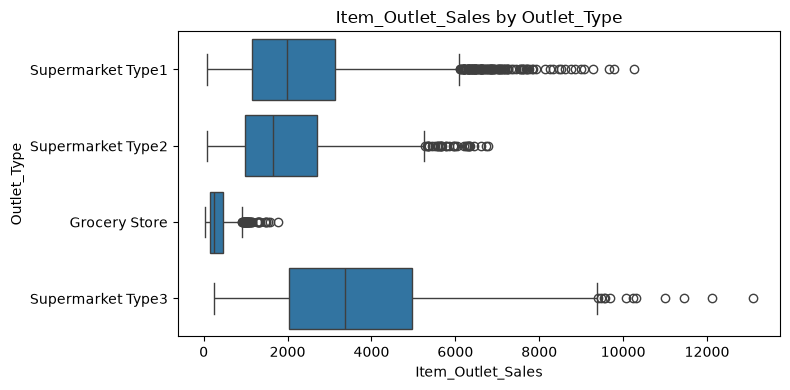

In [50]:
plt.figure(figsize=(8, 4))
sns.boxplot(data=df, y='Outlet_Type', x='Item_Outlet_Sales')
plt.title('Item_Outlet_Sales by Outlet_Type')
plt.tight_layout()
plt.show()

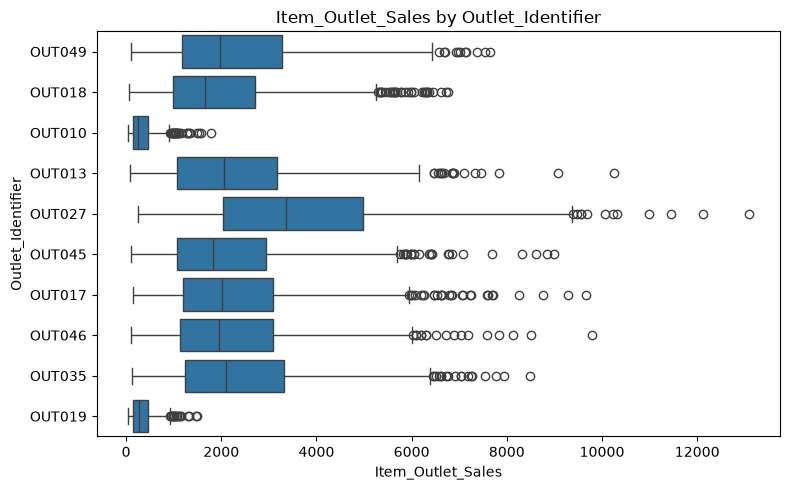

In [51]:
plt.figure(figsize=(8, 5))
sns.boxplot(data=df, y='Outlet_Identifier', x='Item_Outlet_Sales')
plt.title('Item_Outlet_Sales by Outlet_Identifier')
plt.tight_layout()
plt.show()

## Step 3 — Missing Value Treatment

In [52]:
# Combine train and test so both get the same treatment
df["source"] = "train"
df_test["source"] = "test"
data = pd.concat([df, df_test], ignore_index=True)

In [53]:
data.isnull().sum()

Item_Identifier                 0
Item_Weight                  2439
Item_Fat_Content                0
Item_Visibility                 0
Item_Type                       0
Item_MRP                        0
Outlet_Identifier               0
Outlet_Establishment_Year       0
Outlet_Size                  4016
Outlet_Location_Type            0
Outlet_Type                     0
Item_Outlet_Sales            5681
source                          0
dtype: int64

In [54]:
# Item_Weight - fill with the same item's weight from other rows
print("Missing before:", data["Item_Weight"].isnull().sum())

Missing before: 2439


In [55]:
data["Item_Weight"] = data["Item_Weight"].fillna(data.groupby("Item_Identifier")["Item_Weight"].transform("mean"))
data["Item_Weight"] = data["Item_Weight"].fillna(data["Item_Weight"].median())

In [56]:
print("Missing after:", data["Item_Weight"].isnull().sum())

Missing after: 0


In [57]:
# Outlet_Size - fill with the most common size for that Outlet_Type
print(pd.crosstab(data["Outlet_Type"], data["Outlet_Size"].fillna("Missing")))

Outlet_Size        High  Medium  Missing  Small
Outlet_Type                                    
Grocery Store         0       0      925    880
Supermarket Type1  1553    1550     3091   3100
Supermarket Type2     0    1546        0      0
Supermarket Type3     0    1559        0      0


In [58]:
print("Missing before:", data["Outlet_Size"].isnull().sum())

Missing before: 4016


In [59]:
size_mode = data.groupby("Outlet_Type")["Outlet_Size"].agg(lambda s: s.mode()[0])
print(size_mode)

Outlet_Type
Grocery Store         Small
Supermarket Type1     Small
Supermarket Type2    Medium
Supermarket Type3    Medium
Name: Outlet_Size, dtype: str


In [60]:
data["Outlet_Size"] = data["Outlet_Size"].fillna(data["Outlet_Type"].map(size_mode))

In [61]:
print("Missing after:", data["Outlet_Size"].isnull().sum())

Missing after: 0


In [62]:
# Item_Visibility - 0 is not possible for an item on sale, so replace with the item's mean visibility
print("Zero visibility before:", (data["Item_Visibility"] == 0).sum())

Zero visibility before: 879


In [63]:
visibility_mean = data[data["Item_Visibility"] > 0].groupby("Item_Identifier")["Item_Visibility"].mean()
data.loc[data["Item_Visibility"] == 0, "Item_Visibility"] = data.loc[data["Item_Visibility"] == 0, "Item_Identifier"].map(visibility_mean)

In [64]:
print("Zero visibility after:", (data["Item_Visibility"] == 0).sum())

Zero visibility after: 0


In [65]:
data.drop(columns=["Item_Outlet_Sales"]).isnull().sum()

Item_Identifier              0
Item_Weight                  0
Item_Fat_Content             0
Item_Visibility              0
Item_Type                    0
Item_MRP                     0
Outlet_Identifier            0
Outlet_Establishment_Year    0
Outlet_Size                  0
Outlet_Location_Type         0
Outlet_Type                  0
source                       0
dtype: int64

## Step 4 — Outlier Treatment

In [66]:
import numpy as np

In [67]:
train_part = data[data["source"] == "train"]

In [68]:
# mean +/- 3 sigma
for col in ['Item_Weight', 'Item_Visibility', 'Item_MRP', 'Item_Outlet_Sales']:
    m = np.mean(train_part[col])
    sd = np.std(train_part[col])
    lower, upper = m - 3 * sd, m + 3 * sd
    print(f'{col}: 3σ bounds = [{lower:.2f}, {upper:.2f}], outliers = {((train_part[col] < lower) | (train_part[col] > upper)).sum()}')

Item_Weight: 3σ bounds = [-1.06, 26.81], outliers = 0
Item_Visibility: 3σ bounds = [-0.08, 0.22], outliers = 95
Item_MRP: 3σ bounds = [-45.82, 327.81], outliers = 0
Item_Outlet_Sales: 3σ bounds = [-2937.91, 7300.49], outliers = 90


In [69]:
# IQR
for col in ['Item_Weight', 'Item_Visibility', 'Item_MRP', 'Item_Outlet_Sales']:
    Q1, Q3 = train_part[col].quantile([0.25, 0.75])
    IQR = Q3 - Q1
    lower, upper = Q1 - 1.5 * IQR, Q3 + 1.5 * IQR
    print(f'{col}: IQR bounds = [{lower:.2f}, {upper:.2f}], outliers = {((train_part[col] < lower) | (train_part[col] > upper)).sum()}')

Item_Weight: IQR bounds = [-3.31, 28.95], outliers = 0
Item_Visibility: IQR bounds = [-0.07, 0.20], outliers = 143
Item_MRP: IQR bounds = [-43.90, 323.37], outliers = 0
Item_Outlet_Sales: IQR bounds = [-2566.33, 6501.87], outliers = 186


In [70]:
# 99th percentile
for col in ['Item_Weight', 'Item_Visibility', 'Item_MRP', 'Item_Outlet_Sales']:
    upper = np.percentile(train_part[col], 99)
    print(f'{col}: 99th percentile = {upper:.2f}, values above = {(train_part[col] > upper).sum()}')

Item_Weight: 99th percentile = 20.85, values above = 74
Item_Visibility: 99th percentile = 0.23, values above = 86
Item_MRP: 99th percentile = 263.02, values above = 85
Item_Outlet_Sales: 99th percentile = 7366.01, values above = 86


In [71]:
import seaborn as sns
import matplotlib.pyplot as plt

In [72]:
Q1, Q3 = data['Item_Visibility'].quantile([0.25, 0.75])
IQR = Q3 - Q1
lower, upper = Q1 - 1.5 * IQR, Q3 + 1.5 * IQR
print("Number of outliers:", ((data['Item_Visibility'] < lower) | (data['Item_Visibility'] > upper)).sum())

Number of outliers: 259


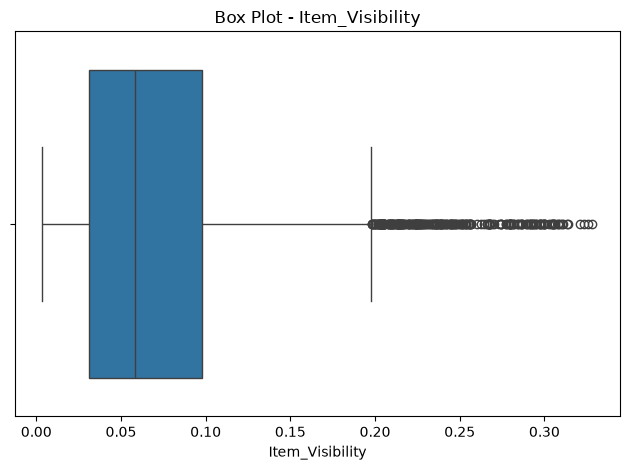

In [73]:
sns.boxplot(data=data, x='Item_Visibility')
plt.title('Box Plot - Item_Visibility')
plt.tight_layout()
plt.show()

In [74]:
# Cap Item_Visibility at the IQR limits
data['Item_Visibility_iqr'] = np.where(data['Item_Visibility'] < lower, lower,
                                np.where(data['Item_Visibility'] > upper, upper, data['Item_Visibility']))
print(data.loc[data['Item_Visibility'] != data['Item_Visibility_iqr'], ['Item_Visibility', 'Item_Visibility_iqr']])

       Item_Visibility  Item_Visibility_iqr
49            0.255395             0.198033
83            0.293418             0.198033
108           0.278974             0.198033
174           0.291865             0.198033
334           0.204700             0.198033
...                ...                  ...
14005         0.240512             0.198033
14037         0.252019             0.198033
14094         0.236595             0.198033
14120         0.205456             0.198033
14191         0.288892             0.198033

[259 rows x 2 columns]


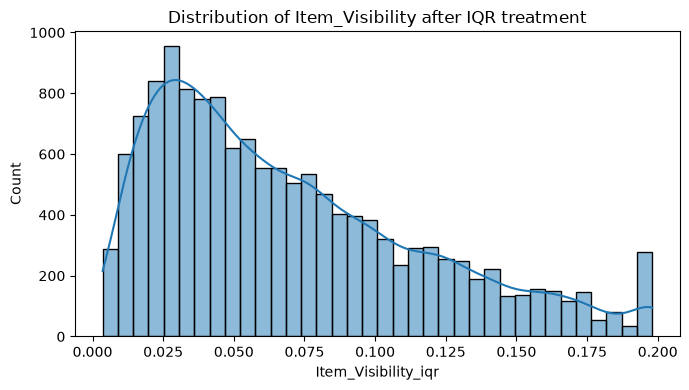

In [75]:
plt.figure(figsize=(7, 4))
sns.histplot(data=data, x='Item_Visibility_iqr', kde=True)
plt.title('Distribution of Item_Visibility after IQR treatment')
plt.tight_layout()
plt.show()

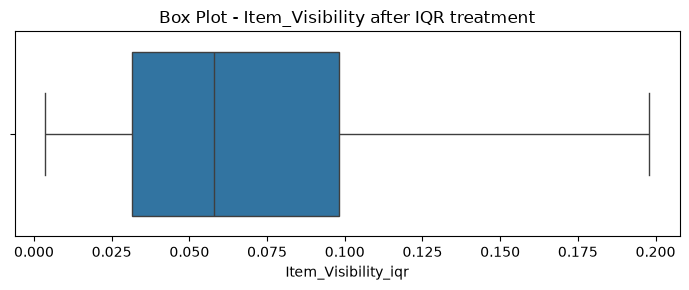

In [76]:
plt.figure(figsize=(7, 3))
sns.boxplot(data=data, x='Item_Visibility_iqr')
plt.title('Box Plot - Item_Visibility after IQR treatment')
plt.tight_layout()
plt.show()

Item_Outlet_Sales outliers are real high sales, so they are kept (not capped).
Item_Weight and Item_MRP have no outliers.

## Step 5 — Variable Creation

In [77]:
# Item_Fat_Content - merge the inconsistent labels
data['Item_Fat_Content'] = data['Item_Fat_Content'].replace({'LF': 'Low Fat', 'low fat': 'Low Fat', 'reg': 'Regular'})

In [78]:
# Item_Category - first two letters of Item_Identifier
data['Item_Category'] = data['Item_Identifier'].str[:2].map({'FD': 'Food', 'DR': 'Drinks', 'NC': 'Non-Consumable'})

In [79]:
# Non-consumable items have no fat content
data.loc[data['Item_Category'] == 'Non-Consumable', 'Item_Fat_Content'] = 'Non-Edible'

In [80]:
data.groupby('Item_Fat_Content')['Item_Outlet_Sales'].mean()

Item_Fat_Content
Low Fat       2163.829268
Non-Edible    2142.721364
Regular       2224.561170
Name: Item_Outlet_Sales, dtype: float64

In [81]:
data.groupby('Item_Category')['Item_Outlet_Sales'].mean()

Item_Category
Drinks            1997.333337
Food              2215.354223
Non-Consumable    2142.721364
Name: Item_Outlet_Sales, dtype: float64

In [82]:
# Outlet_Years - age of the store in 2013
data['Outlet_Years'] = 2013 - data['Outlet_Establishment_Year']
print(data.groupby('Outlet_Years')['Item_Outlet_Sales'].mean())

Outlet_Years
4     1995.498739
6     2340.675263
9     2438.841866
11    2192.384798
14    2348.354635
15     339.351662
16    2277.844267
26    2298.995256
28    2483.677474
Name: Item_Outlet_Sales, dtype: float64


In [83]:
# Item_Visibility_MeanRatio - visibility compared with the item's mean visibility
data['Item_Visibility_MeanRatio'] = data['Item_Visibility'] / data.groupby('Item_Identifier')['Item_Visibility'].transform('mean')
print(data['Item_Visibility_MeanRatio'].describe())

count    14204.000000
mean         1.000000
std          0.200592
min          0.803455
25%          0.901974
50%          0.925261
75%          1.000000
max          1.614811
Name: Item_Visibility_MeanRatio, dtype: float64


In [84]:
# MRP_Band - Item_MRP has 4 clear price groups
data['MRP_Band'] = pd.cut(data['Item_MRP'], bins=[0, 69, 136, 203, np.inf], labels=['Low', 'Medium', 'High', 'Very High'])
print(data.groupby('MRP_Band')['Item_Outlet_Sales'].mean())

MRP_Band
Low           736.474596
Medium       1615.644414
High         2631.226297
Very High    3680.849441
Name: Item_Outlet_Sales, dtype: float64


In [85]:
# Flag whether the outlet is a grocery store
data['Is_Grocery'] = np.where(data['Outlet_Type'] == 'Grocery Store', 1, 0)

In [86]:
# Display the mean Item_Outlet_Sales for each group
print(data.groupby('Is_Grocery')['Item_Outlet_Sales'].mean())

Is_Grocery
0    2449.340208
1     339.828500
Name: Item_Outlet_Sales, dtype: float64


## Step 6 — Variable Transformation

In [87]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

In [88]:
data['Item_Outlet_Sales_log'] = np.log1p(data['Item_Outlet_Sales'])
data['Item_Outlet_Sales_sqrt'] = np.sqrt(data['Item_Outlet_Sales'])
display(data[['Item_Outlet_Sales', 'Item_Outlet_Sales_log', 'Item_Outlet_Sales_sqrt']].head())

,Item_Outlet_Sales,Item_Outlet_Sales_log,Item_Outlet_Sales_sqrt
0,3735.1380,8.225808,61.115775
1,443.4228,6.096776,21.057607
2,2097.2700,7.648868,45.795961
3,732.3800,6.597664,27.062520
4,994.7052,6.903451,31.538947


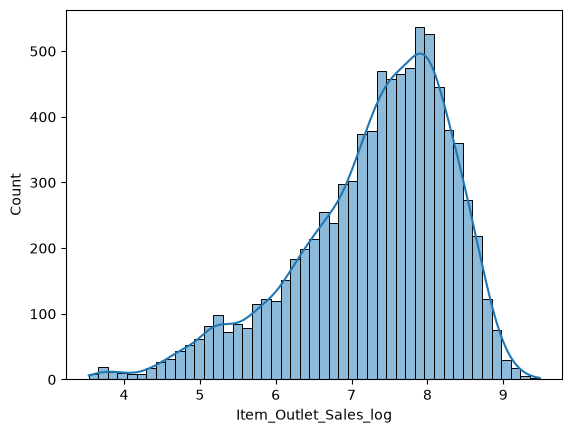

In [89]:
sns.histplot(data['Item_Outlet_Sales_log'], kde=True)
plt.show()

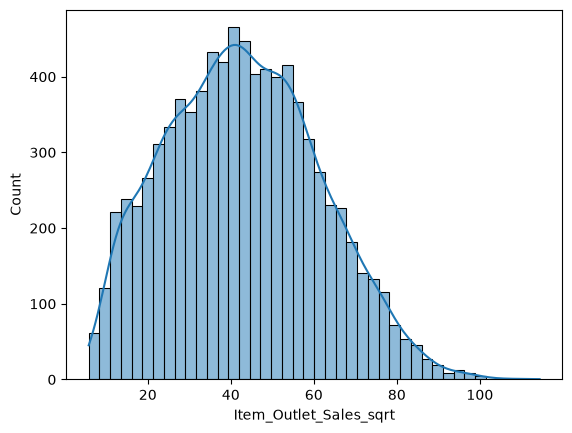

In [90]:
sns.histplot(data['Item_Outlet_Sales_sqrt'], kde=True)
plt.show()

In [91]:
print("Skewness:", data['Item_Outlet_Sales'].skew())
print("Skewness log:", data['Item_Outlet_Sales_log'].skew())
print("Skewness sqrt:", data['Item_Outlet_Sales_sqrt'].skew())

Skewness: 1.1775306028542796
Skewness log: -0.8822656923242799
Skewness sqrt: 0.23467599347099308


In [92]:
data['Item_Visibility_sqrt'] = np.sqrt(data['Item_Visibility'])
data['Item_Visibility_log'] = np.log1p(data['Item_Visibility'])

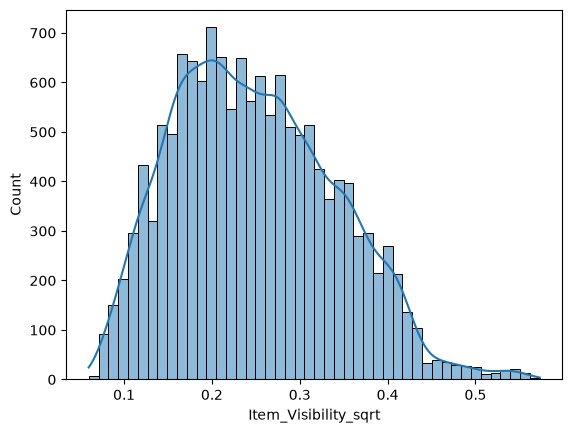

In [93]:
sns.histplot(data['Item_Visibility_sqrt'], kde=True)
plt.show()

In [94]:
print("Skewness:", data['Item_Visibility'].skew())
print("Skewness iqr:", data['Item_Visibility_iqr'].skew())
print("Skewness sqrt:", data['Item_Visibility_sqrt'].skew())
print("Skewness log:", data['Item_Visibility_log'].skew())

Skewness: 1.2336225502822589
Skewness iqr: 0.8619890194508897
Skewness sqrt: 0.4055564223570568
Skewness log: 1.0850228395611172


In [95]:
# Ordinal columns get ordered codes
data['Outlet_Size_code'] = data['Outlet_Size'].map({'Small': 0, 'Medium': 1, 'High': 2})
data['Outlet_Location_code'] = data['Outlet_Location_Type'].map({'Tier 1': 0, 'Tier 2': 1, 'Tier 3': 2})
data['MRP_Band_code'] = data['MRP_Band'].cat.codes

In [96]:
# Nominal columns get one-hot encoded
data['Outlet'] = data['Outlet_Identifier']
data = pd.get_dummies(data, columns=['Item_Fat_Content', 'Item_Category', 'Item_Type', 'Outlet_Type', 'Outlet'], dtype=int)

In [97]:
data = data.drop(columns=['Outlet_Size', 'Outlet_Location_Type', 'MRP_Band', 'Outlet_Establishment_Year'])
data.info()

<class 'pandas.DataFrame'>
RangeIndex: 14204 entries, 0 to 14203
Data columns (total 54 columns):
 #   Column                           Non-Null Count  Dtype  
---  ------                           --------------  -----  
 0   Item_Identifier                  14204 non-null  str    
 1   Item_Weight                      14204 non-null  float64
 2   Item_Visibility                  14204 non-null  float64
 3   Item_MRP                         14204 non-null  float64
 4   Outlet_Identifier                14204 non-null  str    
 5   Item_Outlet_Sales                8523 non-null   float64
 6   source                           14204 non-null  str    
 7   Item_Visibility_iqr              14204 non-null  float64
 8   Outlet_Years                     14204 non-null  int64  
 9   Item_Visibility_MeanRatio        14204 non-null  float64
 10  Is_Grocery                       14204 non-null  int64  
 11  Item_Outlet_Sales_log            8523 non-null   float64
 12  Item_Outlet_Sales_sqrt       

In [98]:
# Split back into train and test and save the cleaned data
train_clean = data[data['source'] == 'train'].drop(columns=['source'])
test_clean = data[data['source'] == 'test'].drop(columns=['source', 'Item_Outlet_Sales', 'Item_Outlet_Sales_log', 'Item_Outlet_Sales_sqrt'])

In [99]:
print("Train:", train_clean.shape, "| Test:", test_clean.shape)
print("Missing values:", train_clean.isnull().sum().sum(), test_clean.isnull().sum().sum())

Train: (8523, 53) | Test: (5681, 50)
Missing values: 0 0


In [100]:
train_clean.to_csv('train_clean.csv', index=False)
test_clean.to_csv('test_clean.csv', index=False)

## Model Building

In [101]:
import pandas as pd
import numpy as np
from sklearn.model_selection import KFold, GridSearchCV, cross_val_score, cross_val_predict
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.compose import TransformedTargetRegressor
from sklearn.linear_model import LinearRegression
from sklearn.neighbors import KNeighborsRegressor
from sklearn.svm import SVR
from sklearn.ensemble import RandomForestRegressor

In [102]:
train = pd.read_csv('train_clean.csv')
test = pd.read_csv('test_clean.csv')

In [103]:
y = train['Item_Outlet_Sales']

In [104]:
# Full feature set - all cleaned features except IDs, target and extra visibility versions
drop_cols = ['Item_Identifier', 'Outlet_Identifier', 'Item_Outlet_Sales', 'Item_Outlet_Sales_log', 'Item_Outlet_Sales_sqrt',
             'Item_Visibility', 'Item_Visibility_iqr', 'Item_Visibility_log']
full_features = [c for c in train.columns if c not in drop_cols]

In [105]:
# Compact feature set - Item_MRP and the outlet dummies (price and store drive sales)
outlet_cols = [c for c in train.columns if c.startswith('Outlet_OUT')]
compact_features = ['Item_MRP'] + outlet_cols

In [106]:
print("Full features:", len(full_features))
print("Compact features:", len(compact_features))

Full features: 45
Compact features: 11


In [107]:
cv = KFold(n_splits=5, shuffle=True, random_state=42)

In [108]:
# Baseline - predict the mean for every row
baseline_rmse = np.sqrt(np.mean((y - np.mean(y)) ** 2))
print("Baseline RMSE:", round(baseline_rmse, 1))

Baseline RMSE: 1706.4


In [109]:
# Linear Regression - raw target vs sqrt target
lr_raw = make_pipeline(StandardScaler(), LinearRegression())
scores = -cross_val_score(lr_raw, train[compact_features], y, cv=cv, scoring='neg_root_mean_squared_error', n_jobs=-1)
print(f'Linear Regression (raw target): CV RMSE = {scores.mean():.1f} ± {scores.std():.1f}')

Linear Regression (raw target): CV RMSE = 1128.7 ± 36.7


In [110]:
lr_model = TransformedTargetRegressor(make_pipeline(StandardScaler(), LinearRegression()),
                                      func=np.sqrt, inverse_func=np.square)
scores = -cross_val_score(lr_model, train[compact_features], y, cv=cv, scoring='neg_root_mean_squared_error', n_jobs=-1)
lr_rmse = scores.mean()
print(f'Linear Regression (sqrt target): CV RMSE = {scores.mean():.1f} ± {scores.std():.1f}')

Linear Regression (sqrt target): CV RMSE = 1098.0 ± 40.8


In [111]:
# KNN - full vs compact features
for name, features in [('full', full_features), ('compact', compact_features)]:
    scores = -cross_val_score(make_pipeline(StandardScaler(), KNeighborsRegressor(n_neighbors=20)),
                              train[features], y, cv=cv, scoring='neg_root_mean_squared_error', n_jobs=-1)
    print(f'KNN k=20 {name}: CV RMSE = {scores.mean():.1f}')

KNN k=20 full: CV RMSE = 1239.5
KNN k=20 compact: CV RMSE = 1094.0


In [112]:
# KNN - tune k
knn_grid = GridSearchCV(
    make_pipeline(StandardScaler(), KNeighborsRegressor()),
    {'kneighborsregressor__n_neighbors': [20, 50, 80, 100, 150, 200],
     'kneighborsregressor__weights': ['uniform', 'distance']},
    cv=cv, scoring='neg_root_mean_squared_error', n_jobs=-1)
knn_grid.fit(train[compact_features], y)

knn_model = knn_grid.best_estimator_
knn_rmse = -knn_grid.best_score_
print("KNN best params:", knn_grid.best_params_)
print("KNN CV RMSE:", round(knn_rmse, 1))

KNN best params: {'kneighborsregressor__n_neighbors': 100, 'kneighborsregressor__weights': 'uniform'}
KNN CV RMSE: 1076.4


In [113]:
# SVR - tune C, gamma and epsilon
svr_grid = GridSearchCV(
    make_pipeline(StandardScaler(), SVR(kernel='rbf')),
    {'svr__C': [300, 1000, 3000],
     'svr__gamma': [0.01, 0.03, 0.1],
     'svr__epsilon': [0.1, 50, 150]},
    cv=cv, scoring='neg_root_mean_squared_error', n_jobs=-1)
svr_grid.fit(train[compact_features], y)

svr_model = svr_grid.best_estimator_
svr_rmse = -svr_grid.best_score_
print("SVR best params:", svr_grid.best_params_)
print("SVR CV RMSE:", round(svr_rmse, 1))

SVR best params: {'svr__C': 1000, 'svr__epsilon': 150, 'svr__gamma': 0.03}
SVR CV RMSE: 1075.4


In [114]:
# Random Forest - tune tree depth, leaf size and features per split
rf_grid = GridSearchCV(
    RandomForestRegressor(n_estimators=300, random_state=42),
    {'max_depth': [6, 7, 8, 10],
     'min_samples_leaf': [20, 50, 100],
     'max_features': [0.5, 1.0]},
    cv=cv, scoring='neg_root_mean_squared_error', n_jobs=-1)
rf_grid.fit(train[full_features], y)

rf_model = rf_grid.best_estimator_
rf_rmse = -rf_grid.best_score_
print("Random Forest best params:", rf_grid.best_params_)
print("Random Forest CV RMSE:", round(rf_rmse, 1))

Random Forest best params: {'max_depth': 7, 'max_features': 0.5, 'min_samples_leaf': 20}
Random Forest CV RMSE: 1078.7


In [115]:
import seaborn as sns
import matplotlib.pyplot as plt

In [116]:
importance = pd.Series(rf_model.feature_importances_, index=full_features).sort_values(ascending=False).head(15)
print(importance.head(5))

Item_MRP                     0.391654
MRP_Band_code                0.158277
Outlet_Type_Grocery Store    0.142857
Is_Grocery                   0.109283
Outlet_OUT027                0.049285
dtype: float64


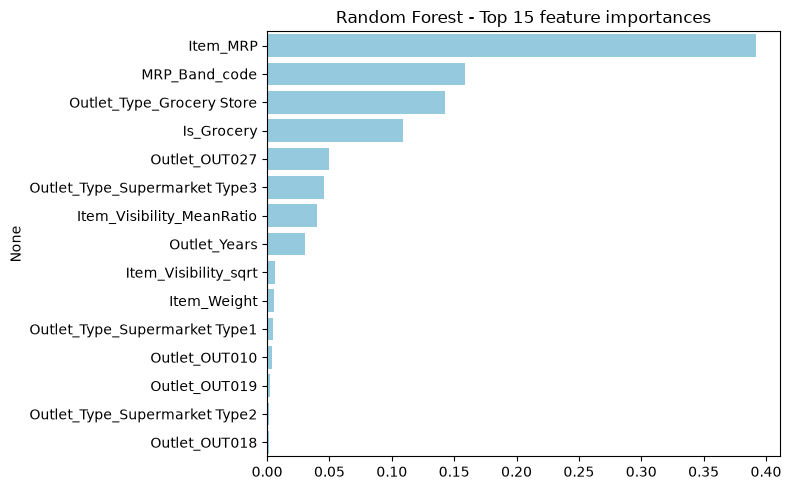

In [117]:
plt.figure(figsize=(8, 5))
sns.barplot(x=importance.values, y=importance.index, color='skyblue')
plt.title('Random Forest - Top 15 feature importances')
plt.tight_layout()
plt.show()

In [118]:
# Model comparison
comparison = pd.DataFrame({
    'Model': ['Mean baseline', 'Linear Regression', 'KNN', 'SVR', 'Random Forest'],
    'CV RMSE': [baseline_rmse, lr_rmse, knn_rmse, svr_rmse, rf_rmse]
}).sort_values('CV RMSE').round(1)
display(comparison)

,Model,CV RMSE
3,SVR,1075.4
2,KNN,1076.4
4,Random Forest,1078.7
1,Linear Regression,1098.0
0,Mean baseline,1706.4


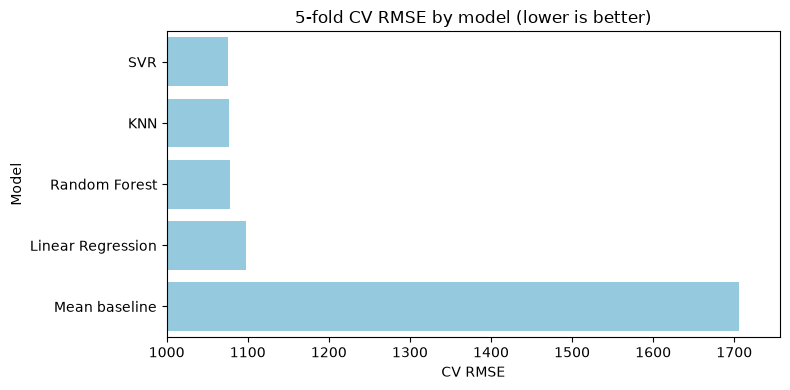

In [119]:
plt.figure(figsize=(8, 4))
sns.barplot(data=comparison, x='CV RMSE', y='Model', color='skyblue')
plt.xlim(1000, comparison['CV RMSE'].max() + 50)
plt.title('5-fold CV RMSE by model (lower is better)')
plt.tight_layout()
plt.show()

In [120]:
# SVR has the lowest CV RMSE, so it is the final model
print("Final model: SVR, CV RMSE =", round(svr_rmse, 1))

Final model: SVR, CV RMSE = 1075.4


In [121]:
# Out-of-fold SVR predictions - every row is predicted by a model that never saw it
svr_oof = cross_val_predict(svr_model, train[compact_features], y, cv=cv, n_jobs=-1)

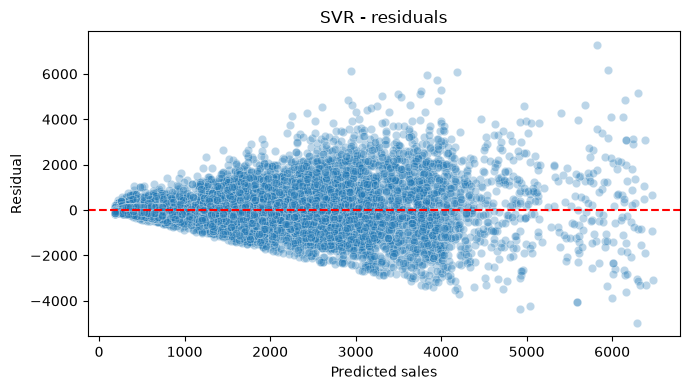

In [122]:
plt.figure(figsize=(7, 4))
sns.scatterplot(x=svr_oof, y=y - svr_oof, alpha=0.3)
plt.axhline(0, color='red', linestyle='--')
plt.xlabel('Predicted sales')
plt.ylabel('Residual')
plt.title('SVR - residuals')
plt.tight_layout()
plt.show()

## Final models and submission files

In [123]:
df_test_raw = pd.read_csv('test_AbJTz2l.csv')

In [124]:
lr_model.fit(train[compact_features], y)
knn_model.fit(train[compact_features], y)
svr_model.fit(train[compact_features], y)
rf_model.fit(train[full_features], y)

lr_pred = np.clip(lr_model.predict(test[compact_features]), 0, None)
knn_pred = np.clip(knn_model.predict(test[compact_features]), 0, None)
svr_pred = np.clip(svr_model.predict(test[compact_features]), 0, None)
rf_pred = np.clip(rf_model.predict(test[full_features]), 0, None)

In [125]:
# Final submission (SVR) - round sales to whole numbers
svr_pred = np.round(svr_pred).astype(int)

In [126]:
for fname, pred in [('submission_svr.csv', svr_pred), ('submission_rf.csv', rf_pred),
                    ('submission_knn.csv', knn_pred), ('submission_lr.csv', lr_pred)]:
    sub = pd.DataFrame({'Item_Identifier': df_test_raw['Item_Identifier'],
                        'Outlet_Identifier': df_test_raw['Outlet_Identifier'],
                        'Item_Outlet_Sales': pred})
    sub.to_csv(fname, index=False)
    print(f'{fname}: rows = {len(sub)}, mean = {sub["Item_Outlet_Sales"].mean():.1f}')

submission_svr.csv: rows = 5681, mean = 2110.1
submission_rf.csv: rows = 5681, mean = 2181.5
submission_knn.csv: rows = 5681, mean = 2182.4
submission_lr.csv: rows = 5681, mean = 2064.1


In [127]:
# Check the final file against the sample submission
sample = pd.read_csv('sample_submission_8RXa3c6 (1).csv')
sub = pd.read_csv('submission_svr.csv')

In [128]:
print("Same columns as sample:", list(sub.columns) == list(sample.columns))
print("Same row order as sample:", (sub[['Item_Identifier', 'Outlet_Identifier']].values == sample[['Item_Identifier', 'Outlet_Identifier']].values).all())
print("Missing / negative values:", sub['Item_Outlet_Sales'].isnull().sum(), (sub['Item_Outlet_Sales'] < 0).sum())
print(sub.head())

Same columns as sample: True
Same row order as sample: True
Missing / negative values: 0 0
  Item_Identifier Outlet_Identifier  Item_Outlet_Sales
0           FDW58            OUT049               1699
1           FDW14            OUT017               1389
2           NCN55            OUT010                581
3           FDQ58            OUT017               2518
4           FDY38            OUT027               5867
